# Classifying ZTF transients with FLARE

**Rubin ML Training School 2026 · Day 2 · AppleCiDEr session**

[FLARE](https://github.com/applecider-ml/flare) is the photometric module of AppleCiDEr and runs on Fritz on every saved ZTF source. In this notebook we load its trained models and its public benchmark: 10,497 ZTF transients of the Bright Transient Survey, each with a class confirmed by a spectrum (SN Ia, core-collapse SN, superluminous SN, AGN, tidal disruption event, cataclysmic variable). We evaluate the classifier, open it up to see why it works, classify from the first days of a light curve, and read its prediction sets.

The notebook has three levels, and you can stop at any of them:

* 🟢 **Run and read**: run the cells in order and read the comments. No machine-learning background is needed.
* 🟡 **Modify**: small changes marked with *Try it*.
* 🔴 **Challenge**: open problems for those who already train models.

Everything runs on a laptop CPU in a few minutes.

## 0. Setup
FLARE is installed from GitHub (it is in the school `requirements.txt`; otherwise run the commented line below once). The trained models come with the package; the benchmark (about 30 MB) is downloaded once into `./data/`.

In [1]:
# %pip install "git+https://github.com/applecider-ml/flare"      # only if `import flare` fails
import tarfile, urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import flare
from flare.benchmark import load_split, SIX as CLASSES
print("FLARE", flare.__version__)

BASE = "https://raw.githubusercontent.com/applecider-ml/flare/main/benchmark/"
DATA = Path("data/flare_benchmark")
for name in ["features_all.parquet", "hosts.csv", "hosts_photoz.csv", "context_gaia_wise.csv", "ps1_position.csv",
             "splits/train.csv", "splits/val.csv", "splits/test.csv", "splits/anomaly.csv", "light_curves.tar.gz"]:
    path = DATA / name
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(BASE + name, path)
if not (DATA / "events").exists():
    with tarfile.open(DATA / "light_curves.tar.gz") as tar:
        tar.extractall(DATA, **({"filter": "data"} if hasattr(tarfile, "data_filter") else {}))

# features (160 from the light curve + 30 from catalogues) and labels of each split, in FLARE's format
data = {s: load_split(s, root=DATA) for s in ["train", "val", "test"]}
X, y, table = ({s: d[i] for s, d in data.items()} for i in range(3))
counts = pd.DataFrame({s: t.cls.value_counts() for s, t in table.items()}).loc[CLASSES]
counts

FLARE 2.0.0


,train,val,test
cls,,,
SN_Ia,5011,1074,1074
SN_CC,1791,384,384
SLSN,109,23,24
AGN,176,37,38
TDE,47,11,10
CV,213,46,45


The classes are very unequal: there are about 100 SNe Ia for every TDE. Keep this in mind when we choose how to measure performance.

### What a light curve looks like
Each object is a file with one row per detection: the time since the first detection, the band (0 = *g*, 1 = *r*, 2 = *i*) and the flux as $\log_{10}$ of the flux in µJy, so that the AB magnitude is $m = 23.9 - 2.5\,\log_{10} f$.

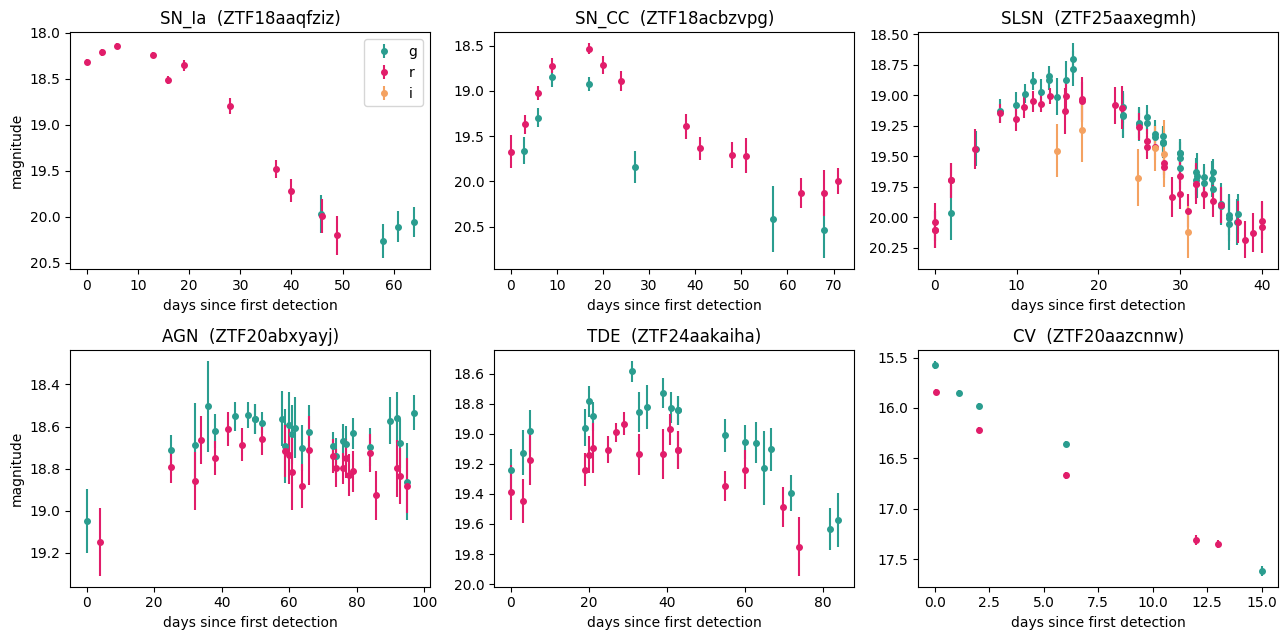

In [2]:
def load_lc(obj_id):
    """Detections of one object (t = days since the first detection)."""
    z = np.load(DATA / "events" / f"{obj_id}.npz")
    d = pd.DataFrame(z["data"], columns=[str(c) for c in z["columns"]])
    return pd.DataFrame({"t": d["dt"], "band": d["band_id"].astype(int),
                         "mag": 23.9 - 2.5 * d["logflux"], "mag_err": 2.5 * d["logflux_err"]})

COLORS = {0: "#2a9d8f", 1: "#e11d6a", 2: "#f4a261"}
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
for ax, cls in zip(axes.flat, CLASSES):
    obj = table["train"].query("cls == @cls").obj_id.iloc[3]
    lc = load_lc(obj)
    for b, name in enumerate("gri"):
        s = lc[lc.band == b]
        ax.errorbar(s.t, s.mag, s.mag_err, fmt="o", ms=4, color=COLORS[b], label=name)
    ax.invert_yaxis(); ax.set_title(f"{cls}  ({obj})"); ax.set_xlabel("days since first detection")
axes[0, 0].set_ylabel("magnitude"); axes[1, 0].set_ylabel("magnitude"); axes[0, 0].legend()
fig.tight_layout()

🟡 *Try it*: change `.iloc[3]` to another number to see other members of each class. Which classes look alike?

## 1. FLARE out of the box

A machine-learning classifier needs a fixed-length description of every object, its **features**. FLARE computes 160 of them from each light curve (amplitudes, rise and decline times, colours, fits of simple light-curve shapes) and adds 30 from catalogues. Its model is a set of **gradient-boosted decision trees** (LightGBM): many small decision trees, each correcting the errors of the previous ones. It first chooses among five groups (SN Ia, SN CC + SLSN, AGN, TDE, CV) and then separates the SLSNe from the other core-collapse SNe.

The shipped classifier was trained on the `train` and `val` splits, so the `test` split, which it never saw, gives an honest score.

FLARE (shipped model)              accuracy 0.926   balanced accuracy 0.843   macro F1 0.847


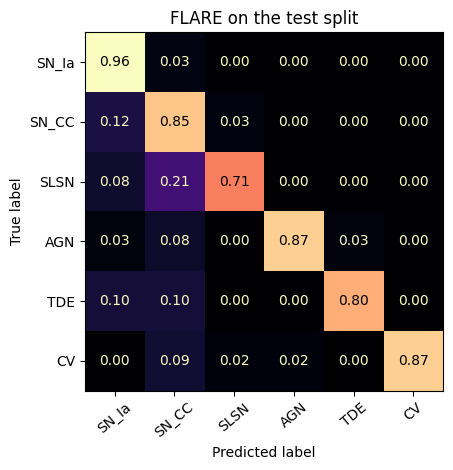

In [3]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

clf = flare.load_classifier()                       # six classes, light curve + context
Xt = X["test"].reindex(columns=clf.feature_names)
pred = np.array([CLASSES.index(c) for c in clf.predict(Xt)])

def report(pred, name):
    print(f"{name:34s} accuracy {accuracy_score(y['test'], pred):.3f}   "
          f"balanced accuracy {balanced_accuracy_score(y['test'], pred):.3f}   "
          f"macro F1 {f1_score(y['test'], pred, average='macro'):.3f}")
    return pd.Series(f1_score(y["test"], pred, average=None), index=CLASSES, name=name)

f1 = {"FLARE": report(pred, "FLARE (shipped model)")}

def show_confusion(pred, title):
    cm = confusion_matrix(y["test"], pred, normalize="true")
    fig, ax = plt.subplots(figsize=(5.5, 4.8))
    ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(ax=ax, cmap="magma", values_format=".2f", colorbar=False)
    ax.set_title(title); plt.xticks(rotation=40); fig.tight_layout()
show_confusion(pred, "FLARE on the test split")

**Accuracy** is the fraction of correct labels. With 68% SNe Ia in the test set, a model that answers "SN Ia" every time already has an accuracy of 0.68, so accuracy says little about the rare classes. Two scores treat every class equally:

* **balanced accuracy**: the mean over classes of the fraction of each class that is found (the recall);
* **macro F1**: the mean over classes of the F1 score, which combines recall with the purity of each predicted label.

In the confusion matrix each row is a true class, normalised to one. Where do the SLSNe and the TDEs go when they are missed?

## 2. Under the hood: what the light curve cannot tell

Some classes are defined by information that a *g* and *r* light curve does not carry. A superluminous SN is defined by its **luminosity**, which needs a distance. A TDE happens in the **nucleus** of a galaxy. An AGN is a persistent nuclear source with the **infrared colours** of hot dust. A CV is in **our Galaxy** and has no host. FLARE looks these up in catalogues at the time of the alert:

| block | catalogue | what it supplies |
|---|---|---|
| host | Pan-STARRS | distance to the nearest galaxy, its brightness and colours |
| `M_pseudo` | Legacy Surveys photo-z | peak magnitude minus the distance modulus of the host photometric redshift |
| point source | Gaia, WISE | parallax and proper motion (a star), WISE colours (hot dust of an AGN) |
| counterpart | Pan-STARRS | a source at the position before the outburst |

To see what each part contributes, we train small classifiers of our own, with and without the catalogue columns.

In [4]:
import lightgbm as lgb
LC_COLS = list(pd.read_parquet(DATA / "features_all.parquet").columns.drop("obj_id"))
CTX_COLS = [c for c in clf.feature_names if c not in LC_COLS]
print(len(LC_COLS), "light-curve features;", len(CTX_COLS), "context features, e.g.", CTX_COLS[:6])

def train(cols, class_weight="balanced", seed=0):
    model = lgb.LGBMClassifier(n_estimators=2000, learning_rate=0.05, num_leaves=31,
                               class_weight=class_weight, random_state=seed, verbose=-1)
    model.fit(X["train"][cols], y["train"], eval_set=[(X["val"][cols], y["val"])],
              callbacks=[lgb.early_stopping(100, verbose=False)])
    return model

m_lc_u = train(LC_COLS, class_weight=None)
f1["ours: light curve, unweighted"] = report(m_lc_u.predict(X["test"][LC_COLS]), "ours: light curve, unweighted")
m_lc = train(LC_COLS)
f1["ours: light curve"] = report(m_lc.predict(X["test"][LC_COLS]), "ours: light curve, class weights")
m_ctx = train(LC_COLS + CTX_COLS)
f1["ours: + context"] = report(m_ctx.predict(X["test"][LC_COLS + CTX_COLS]), "ours: + context, class weights")
pd.DataFrame(f1).round(2)

160 light-curve features; 30 context features, e.g. ['host_sep', 'host_r', 'host_i', 'host_gr', 'host_ri', 'host_iz']


ours: light curve, unweighted      accuracy 0.892   balanced accuracy 0.602   macro F1 0.678


ours: light curve, class weights   accuracy 0.893   balanced accuracy 0.672   macro F1 0.692


ours: + context, class weights     accuracy 0.929   balanced accuracy 0.873   macro F1 0.863


,FLARE,"ours: light curve, unweighted",ours: light curve,ours: + context
SN_Ia,0.96,0.95,0.95,0.96
SN_CC,0.86,0.80,0.81,0.87
SLSN,0.64,0.39,0.32,0.64
AGN,0.89,0.60,0.64,0.92
TDE,0.80,0.53,0.60,0.86
CV,0.93,0.80,0.84,0.93


* **Class weights** (`class_weight="balanced"`) make each class carry the same total weight in training; without them the model mostly learns SNe Ia.
* **Context** helps most for the TDEs, the AGN and the SLSNe, the classes defined by position, infrared colour and luminosity. In the FLARE paper the macro F1 rises from 0.72 to 0.83 (five-fold cross-validation).
* Missing catalogue values stay missing (`NaN`): the trees learn what an absent host means (a CV has none). Do not fill them with a mean.

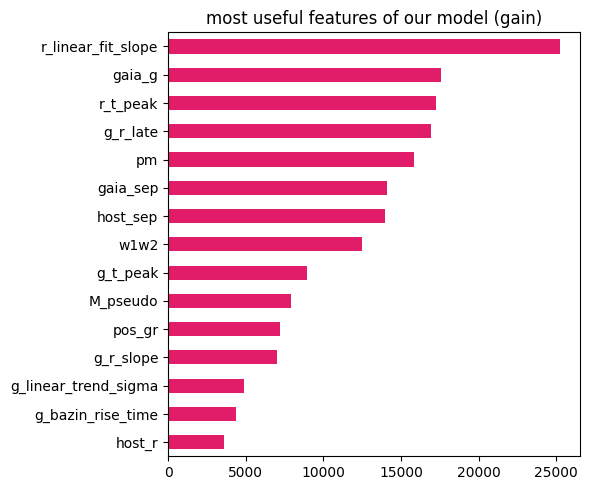

In [5]:
imp = pd.Series(m_ctx.booster_.feature_importance("gain"), index=LC_COLS + CTX_COLS).nlargest(15)
imp[::-1].plot.barh(figsize=(6, 5), color="#e11d6a", title="most useful features of our model (gain)"); plt.tight_layout()

🟡 *Try it*: which context features are in the top 15? Look up what `host_sep`, `w1w2` and `M_pseudo` measure in the table above.

🔴 **Challenge**: missing values can also *leak* the label. In the BTS sample a spectroscopic redshift exists for almost every supernova and for almost no CV or AGN, so a model given `z_spec` (in `hosts_photoz.csv`) learns "has a redshift" instead of the physics. Add it and see. FLARE trains with each context block removed for a random 30% of the objects; implement that and compare.

## 3. How early can we classify?

A classification is most useful early, while there is still time to take a spectrum. FLARE ships models trained on light curves cut at 5, 10 and 20 days after the first detection. We cut every test light curve at day $h$, recompute the 160 features from what remains (`features_from_files`), and recompute `M_pseudo` from the peak seen so far, since the full-curve peak would leak information from the future.

FLARE, first 5 days                accuracy 0.795   balanced accuracy 0.621   macro F1 0.641


FLARE, first 10 days               accuracy 0.832   balanced accuracy 0.684   macro F1 0.686


FLARE, first 20 days               accuracy 0.875   balanced accuracy 0.769   macro F1 0.784


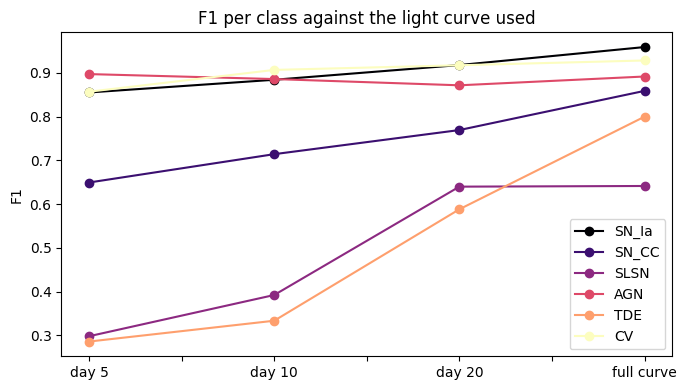

In [6]:
import contextlib, os
from flare.context import lumdist_mpc

@contextlib.contextmanager
def quiet_stderr():
    """Silence the C++ fitting library, which prints a warning for every light curve it cannot fit."""
    saved = os.dup(2)
    with open(os.devnull, "w") as null:
        os.dup2(null.fileno(), 2)
        try:
            yield
        finally:
            os.dup2(saved, 2); os.close(saved)

paths = [str(DATA / "events" / f"{o}.npz") for o in table["test"].obj_id]
z_phot = pd.read_csv(DATA / "hosts_photoz.csv").drop_duplicates("obj_id").set_index("obj_id")["z_phot"].reindex(table["test"].obj_id).to_numpy(float)
context = X["test"][[c for c in CTX_COLS if c != "M_pseudo"]].reset_index(drop=True)

early = {}
for h in [5, 10, 20]:
    clf_h = flare.load_classifier(horizon_days=h)
    with quiet_stderr():
        Xh = clf_h.features_from_files(paths, context=context, horizon_days=h)
    peak_h = 23.9 - 2.5 * Xh[["g_logflux_peak", "r_logflux_peak", "i_logflux_peak"]].max(axis=1).to_numpy()
    with np.errstate(invalid="ignore", divide="ignore"):
        Xh["M_pseudo"] = peak_h - 5 * np.log10(lumdist_mpc(z_phot) * 1e5)
    pred_h = np.array([CLASSES.index(c) for c in clf_h.predict(Xh.reindex(columns=clf_h.feature_names))])
    early[f"day {h}"] = report(pred_h, f"FLARE, first {h} days")
early["full curve"] = f1["FLARE"]
E = pd.DataFrame(early)
ax = E.T.plot(marker="o", figsize=(7, 4), cmap="magma", title="F1 per class against the light curve used")
ax.set_ylabel("F1"); plt.tight_layout()

Which classes are decided within days, and which need the full light curve? A CV or an AGN often reveals itself through its context, while separating an SLSN from a normal core-collapse SN needs the slow rise and the luminosity.

(The early models were trained on the BTS `train` and `val` splits together with spectroscopically confirmed sources from Fritz; the BTS `test` split stays unseen.)

### Write your own features
Features are where astrophysical intuition enters. Below are a dozen hand-made features at day 5; a small model trained on them can be compared with FLARE at the same day.

In [7]:
def simple_features(lc, h):
    """A dozen hand-made features of the light curve up to day h."""
    lc = lc[lc.t <= h]
    out = {"n_det": len(lc), "span": lc.t.max() - lc.t.min()}
    for b, name in [(0, "g"), (1, "r")]:
        s = lc[lc.band == b].sort_values("t")
        if len(s) == 0:
            continue
        i = s.mag.values.argmin()
        out[f"{name}_peak"] = s.mag.min()
        out[f"{name}_last_minus_peak"] = s.mag.values[-1] - s.mag.min()
        out[f"{name}_t_peak"] = s.t.values[i]
        if i > 0:
            out[f"{name}_rise_rate"] = (s.mag.values[0] - s.mag.values[i]) / max(s.t.values[i] - s.t.values[0], 0.1)
    g, r = lc[lc.band == 0], lc[lc.band == 1]
    if len(g) and len(r):
        dt = np.abs(g.t.values[:, None] - r.t.values[None, :])
        i, j = np.unravel_index(dt.argmin(), dt.shape)
        if dt[i, j] < 1.5:
            out["g_minus_r"] = g.mag.values[i] - r.mag.values[j]    # colour from the closest g and r pair
    return out

H = 5
own = {s: pd.DataFrame([simple_features(load_lc(o), H) for o in t.obj_id]).astype(float) for s, t in table.items()}
own = {s: pd.concat([f, X[s][[c for c in CTX_COLS if c != "M_pseudo"]].reset_index(drop=True)], axis=1) for s, f in own.items()}
cols = list(own["train"].columns)
m_own = lgb.LGBMClassifier(n_estimators=2000, learning_rate=0.05, class_weight="balanced", random_state=0, verbose=-1)
m_own.fit(own["train"][cols], y["train"], eval_set=[(own["val"].reindex(columns=cols), y["val"])], callbacks=[lgb.early_stopping(100, verbose=False)])
_ = report(m_own.predict(own["test"].reindex(columns=cols)), f"ours: simple features, day {H}")

ours: simple features, day 5       accuracy 0.775   balanced accuracy 0.611   macro F1 0.619


🟡 *Try it*: add a feature to `simple_features` (the scatter of the magnitudes, the number of nights, a decline rate) and rerun the cell. How close can a dozen features get to FLARE at day 5?

## 4. Saying "I don't know": conformal prediction sets

A probability of 0.6 for "SN Ia" is a guess. For follow-up we want a guarantee: a set of classes that contains the true class for at least 90% of the objects. **Conformal prediction** builds such sets from calibration objects, without assumptions about the model.

For each class $c$, take calibration objects of that class, compute the score $s = 1 - p_c$ (how surprised the model is by the true class) and keep its 90% quantile $\hat q_c$. A new object receives every class with $1 - p_c \le \hat q_c$. Doing this per class (*Mondrian* conformal prediction) gives the 90% guarantee for every class separately, including the rare ones.

First we build the sets ourselves for our model of section 2, calibrated on the validation split it did not train on:

In [8]:
ALPHA = 0.10
P_val, P_test = m_ctx.predict_proba(X["val"][LC_COLS + CTX_COLS]), m_ctx.predict_proba(X["test"][LC_COLS + CTX_COLS])
qhat = np.full(len(CLASSES), np.inf)
for c in range(len(CLASSES)):
    s = np.sort(1 - P_val[y["val"] == c, c]); n = len(s)
    k = int(np.ceil((n + 1) * (1 - ALPHA)))
    qhat[c] = s[k - 1] if k <= n else np.inf     # too few calibration objects: the class is always in the set
sets_ours = (1 - P_test) <= qhat[None, :]

def set_table(sets, n_cal=None):
    out = pd.DataFrame({"coverage": [sets[y["test"] == c, c].mean() for c in range(6)],
                        "mean_set_size": [sets[y["test"] == c].sum(1).mean() for c in range(6)],
                        "single_class": [(sets[y["test"] == c].sum(1) == 1).mean() for c in range(6)]}, index=CLASSES)
    if n_cal is not None:
        out.insert(0, "n_calibration", n_cal)
    print(f"overall coverage {sets[np.arange(len(sets)), y['test']].mean():.3f}, single-class sets {(sets.sum(1) == 1).mean():.2f}")
    return out.round(2)
set_table(sets_ours, [int((y["val"] == c).sum()) for c in range(6)])

overall coverage 0.895, single-class sets 0.88


,n_calibration,coverage,mean_set_size,single_class
SN_Ia,1074,0.88,1.04,0.91
SN_CC,384,0.93,1.17,0.82
SLSN,23,1.00,1.42,0.67
AGN,37,0.95,1.08,0.92
TDE,11,0.90,1.90,0.50
CV,46,0.98,1.29,0.82


Look at the TDEs: a class needs at least $\lceil 1/\alpha \rceil - 1 = 9$ calibration members for a finite threshold, and the validation split has only 11, so the threshold is noisy and the TDE sets are wide. FLARE calibrates **cross-conformally**: the scores of all five folds of a cross-validation are pooled, which gives every class five times more calibration members. These are the sets that FLARE returns:

In [9]:
sets_flare = np.array([[c in s for c in CLASSES] for s in clf.prediction_sets(Xt)])
set_table(sets_flare)

overall coverage 0.897, single-class sets 0.91


,coverage,mean_set_size,single_class
SN_Ia,0.89,0.99,0.95
SN_CC,0.91,1.12,0.84
SLSN,0.96,1.62,0.38
AGN,0.87,1.11,0.89
TDE,0.90,1.10,0.90
CV,0.84,1.04,0.96


In [10]:
one = clf.conformal_report(Xt.iloc[[0]])[0]     # what the Fritz service reports for one object
{k: one[k] for k in ["predicted", "set", "credibility", "confidence", "empirical_coverage"]}

{'predicted': 'SN_Ia',
 'set': ['SN_Ia'],
 'credibility': 0.296910943148209,
 'confidence': 0.9788602941176471,
 'empirical_coverage': 0.9}

* **coverage**: the fraction of test objects whose set contains the true class; it should be close to 0.90 for every class.
* **mean set size**: the price of the guarantee. A set {SLSN, SN CC} is an honest answer for an object that the light curve cannot settle: it says *take a spectrum*.
* On Fritz, FLARE posts a classification only when the 90% set holds a single class.

🟡 *Try it*: set `ALPHA = 0.05` and `ALPHA = 0.32` in our own sets. How do the coverage and the set size change?

🔴 **Challenge**: implement cross-conformal calibration for our model (five folds on `train`) and compare its TDE coverage and set size with the single split.

## Take-away

1. Report balanced scores (balanced accuracy, macro F1) when the classes are unequal.
2. The light curve carries the shape; catalogues carry distance, position in the host and stellar nature. Some classes need both.
3. Most classes are decided within days; SLSNe and TDEs need longer light curves.
4. A prediction set with a coverage guarantee turns "the model is unsure" into an actionable answer.

**Next session**: what happens when an object belongs to *none* of the six classes? We score these light curves for novelty with FLARE's anomaly layer and LUNA.

*Further reading*: Sasli et al. 2026, [arXiv:2610.30656](https://arxiv.org/abs/2610.30656) (FLARE); Junell, Sasli et al. 2025, [arXiv:2507.16088](https://arxiv.org/abs/2507.16088) (AppleCiDEr).